# Прогноз солнечной активности: SARIMA

Ноутбук исследует подготовленный ряд солнечных пятен: декомпозиция STL, анализ автокорреляций, тест Дики—Фуллера, подбор параметров и оценка SARIMA на отложенном временном отрезке.

Входной файл создаётся ноутбуком [02 — Подготовка солнечной активности](02-sunspots-data-preparation.ipynb). Запускайте ячейки последовательно.


In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../data/processed/sunspots_processed.csv', index_col=0)

In [3]:
df = df.rename(columns={'Month': 'ds', 'Sunspots': 'y'})
df['unique_id'] = 'Sunspot'
df = df[['unique_id', 'ds', 'y']]

In [4]:
train, test = train_test_split(df, test_size=0.2, shuffle=False)

In [5]:
train

,unique_id,ds,y
0,Sunspot,1749-01-01,58.0
1,Sunspot,1749-02-01,62.6
2,Sunspot,1749-03-01,70.0
3,Sunspot,1749-04-01,55.7
4,Sunspot,1749-05-01,85.0
...,...,...,...
2251,Sunspot,1936-08-01,87.0
2252,Sunspot,1936-09-01,76.0
2253,Sunspot,1936-10-01,89.0
2254,Sunspot,1936-11-01,115.4


# STL-декомпозиция

In [6]:
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

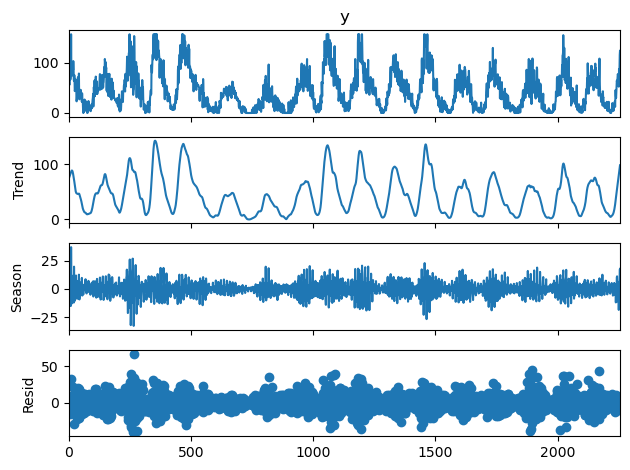

In [7]:
stl = STL(train['y'], period=12)
result = stl.fit()
result.plot();

В данном ряде отсутствует тренд, однако присутствует сезонность. Характер ошибок случаен

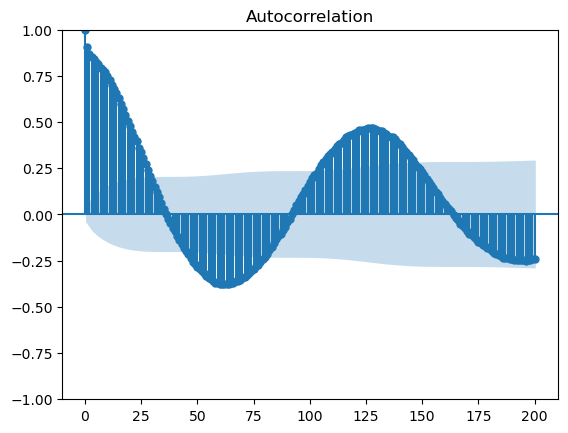

In [8]:
plot_acf(train['y'], lags=200);

Величина сезонного лага: 130 месяцев (10,8 лет)

# Исследуем на стационарность

In [9]:
from statsmodels.tsa.stattools import adfuller

In [10]:
adfuller(train['y'])[1]

7.016030103771744e-13

Низкое p-value говорит о стационарности ряда. Будем использовать модель SARIMA, так как в ряде присутствует сезонность

# Подбор параметров p, P, q, Q

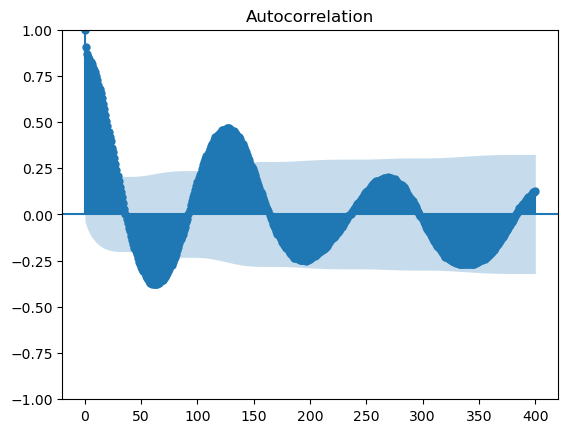

In [11]:
plot_acf(train['y'], lags=400);

In [12]:
q = 29
Q = 1

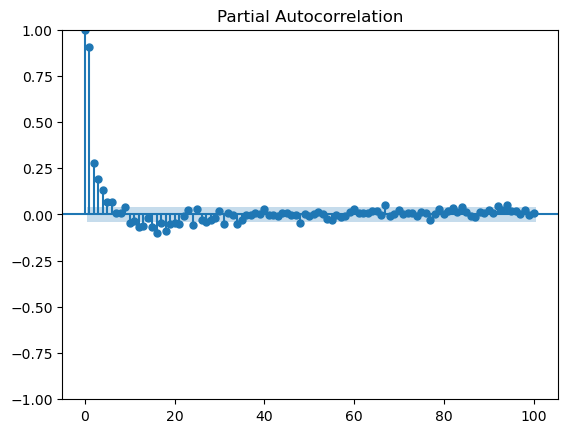

In [9]:
plot_pacf(train['y'], lags=400);

In [14]:
p = 7
P = 2

# Обучение SARIMA

In [15]:
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA, ARIMA

C:\Users\Denis\miniconda3\envs\ts\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\Denis\miniconda3\envs\ts\lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


In [16]:
auto_arima = AutoARIMA(
    seasonal=True,
    season_length=130,
    max_p=p,
    max_P=P,
    max_q=q,
    max_Q=Q,
    stepwise=True,
    trace=True
)

sf = StatsForecast(
    models=[auto_arima],
    freq='MS',
    n_jobs=-1
)

In [17]:
cv_results = sf.cross_validation(
    df=train.iloc[1500:],
    h=12,
    n_windows=3,
    step_size=12
)


ARIMA(2,0,2)(1,1,1)[130] with drift        :inf

ARIMA(0,0,0)(0,1,0)[130] with drift        :5474.965514678074

ARIMA(1,0,0)(1,1,0)[130] with drift        :inf

ARIMA(0,0,1)(0,1,1)[130] with drift        :inf

ARIMA(0,0,0)(0,1,0)[130]                   :5474.137485612778

ARIMA(0,0,0)(1,1,0)[130] with drift        :inf

ARIMA(0,0,0)(0,1,1)[130] with drift        :inf

ARIMA(0,0,0)(1,1,1)[130] with drift        :inf

ARIMA(1,0,0)(0,1,0)[130] with drift        :5159.44425684901

ARIMA(1,0,0)(0,1,1)[130] with drift        :inf

ARIMA(1,0,0)(1,1,1)[130] with drift        :inf

ARIMA(2,0,0)(0,1,0)[130] with drift        :5129.579480846818

ARIMA(2,0,0)(1,1,0)[130] with drift        :inf

ARIMA(2,0,0)(0,1,1)[130] with drift        :inf

ARIMA(2,0,0)(1,1,1)[130] with drift        :inf

ARIMA(3,0,0)(0,1,0)[130] with drift        :5115.933673236684

ARIMA(3,0,0)(1,1,0)[130] with drift        :inf

ARIMA(3,0,0)(0,1,1)[130] with drift        :inf

ARIMA(3,0,0)(1,1,1)[130] with drift        :inf


In [18]:
cv_results

,unique_id,ds,cutoff,y,AutoARIMA
0,Sunspot,1934-01-01,1933-12-01,3.40,1.143881
1,Sunspot,1934-02-01,1933-12-01,7.80,2.550616
2,Sunspot,1934-03-01,1933-12-01,4.30,-0.298485
3,Sunspot,1934-04-01,1933-12-01,11.30,5.988472
4,Sunspot,1934-05-01,1933-12-01,19.70,-0.468725
5,Sunspot,1934-06-01,1933-12-01,6.70,-3.467877
6,Sunspot,1934-07-01,1933-12-01,9.30,9.713969
7,Sunspot,1934-08-01,1933-12-01,8.30,8.515902
8,Sunspot,1934-09-01,1933-12-01,4.00,6.981495
9,Sunspot,1934-10-01,1933-12-01,5.70,-0.190112


In [20]:
from utilsforecast.losses import mae, rmse, mape
from utilsforecast.evaluation import evaluate

evaluation = evaluate(
    cv_results,
    metrics=[mae, rmse, mape],
    models=['AutoARIMA']
)

In [21]:
evaluation

,unique_id,cutoff,metric,AutoARIMA
0,Sunspot,1933-12-01,mae,6.793652
1,Sunspot,1934-12-01,mae,16.935450
2,Sunspot,1935-12-01,mae,16.579611
3,Sunspot,1933-12-01,rmse,8.815894
4,Sunspot,1934-12-01,rmse,23.456159
5,Sunspot,1935-12-01,rmse,19.618868
6,Sunspot,1933-12-01,mape,0.783138
7,Sunspot,1934-12-01,mape,0.439910
8,Sunspot,1935-12-01,mape,0.217542


In [23]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [24]:
model = SARIMAX(
    train['y'],
    order=(7, 0, 1),
    seasonal_order=(0, 1, 0, 130)
)

results = model.fit()

C:\Users\Denis\miniconda3\envs\ts\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [25]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                      SARIMAX Results                                       
============================================================================================
Dep. Variable:                                    y   No. Observations:                 2256
Model:             SARIMAX(7, 0, 1)x(0, 1, [], 130)   Log Likelihood               -9402.311
Date:                              Sun, 19 Apr 2026   AIC                          18822.621
Time:                                      23:10:17   BIC                          18873.579
Sample:                                           0   HQIC                         18841.274
                                             - 2256                                         
Covariance Type:                                opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3933      0.066     -5.944      0.000      -0.523      -0.264
ar.L2          0.5648      0.038     14.869      0.000       0.490       0.639
ar.L3          0.1853      0.025      7.344      0.000       0.136       0.235
ar.L4          0.1557      0.023      6.753      0.000       0.110       0.201
ar.L5          0.1106      0.023      4.823      0.000       0.066       0.155
ar.L6          0.1289      0.020      6.386      0.000       0.089       0.168
ar.L7          0.1022      0.018      5.590      0.000       0.066       0.138
ma.L1          0.9156      0.064     14.304      0.000       0.790       1.041
sigma2       404.4672      8.831     45.802      0.000     387.159     421.775
===================================================================================
Ljung-Box (L1) (Q):                   0.01   Jarque-Bera (JB):               363.81
Prob(Q):                              0.92   Prob(JB):                         0.00
Heteroskedasticity (H):               0.85   Skew:                            -0.04
Prob(H) (two-sided):                  0.03   Kurtosis:                         5.02
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

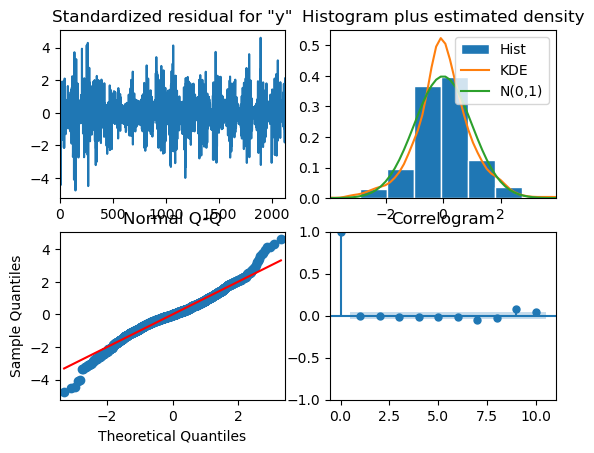

In [26]:
results.plot_diagnostics();

In [27]:
pred = results.forecast(steps=len(test))
pred

2256    95.215290
2257    65.790395
2258    91.729216
2259    97.862739
2260    78.905209
          ...    
2815    80.160945
2816    78.184079
2817    73.517801
2818    41.859274
2819    61.210383
Name: predicted_mean, Length: 564, dtype: float64

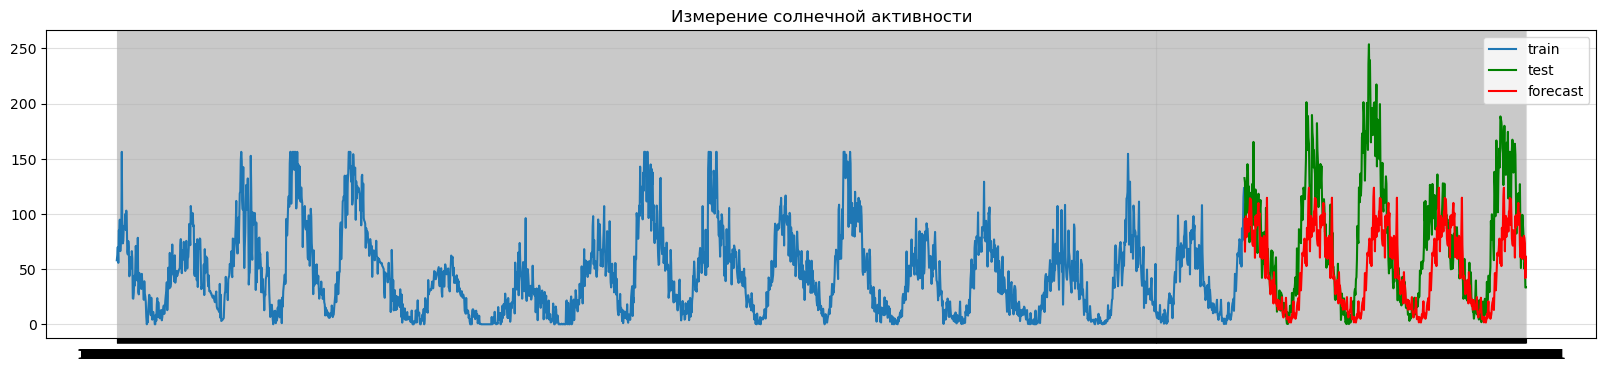

In [28]:
plt.figure(figsize=(20, 4))
plt.plot(train['ds'], train['y'], label='train')
plt.plot(test['ds'], test['y'], c='g', label='test')
plt.plot(test['ds'], pred, c='r', label='forecast')
plt.title('Измерение солнечной активности')
plt.legend()
plt.grid(alpha=0.4)

In [29]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

In [30]:
print(f"MAE: {mean_absolute_error(test['y'], pred)}")
print(f"MSE: {mean_squared_error(test['y'], pred)}")
print(f"MAPE: {mean_absolute_percentage_error(test['y'], pred)}")
print(f"R2: {r2_score(test['y'], pred)}")

MAE: 34.98505599175982
MSE: 2509.444889518945
MAPE: 0.9585884572243433
R2: 0.17362203048661073
